In [1]:
!pip install rdkit
!pip install py3Dmol

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.4/37.4 MB 30.9 MB/s eta 0:00:00


In [2]:
from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.drawOptions.addAtomIndices = True


In [3]:
from rdkit.Chem import Draw

In [5]:
from rdkit import Chem
from rdkit.Chem import AllChem, rdFreeSASA, rdMolDescriptors
import urllib.request
import py3Dmol

# ==============================================================================
# 1. OBTENER LOSARTÁN DESDE PUBCHEM (CID: 3821) Y PREPARAR ESTRUCTURA 3D
# ==============================================================================
# cid = '3821'  # Losartán
# cid = '36314' #taxol
# cid = '640180' # clonazepam
cid = '186907' #aflatoxin b1
url = f'https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/{cid}/property/SMILES/TXT'

req = urllib.request.urlopen(url)
smiles = req.read().decode('utf-8').strip()
# smiles = 'CCCCCOCCCCC(C)CC' #por si no esta reportado el cid

# Generar molécula con RDKit y optimizar geometría 3D
mol = Chem.MolFromSmiles(smiles)
mol = Chem.AddHs(mol)
AllChem.EmbedMolecule(mol, randomSeed=42)
AllChem.MMFFOptimizeMolecule(mol)

# ==============================================================================
# 2. CÁLCULO DE PROPIEDADES EN RDKIT (CORREGIDO)
# ==============================================================================
# A. Cargas Parciales de Gasteiger
AllChem.ComputeGasteigerCharges(mol)

# B. Contribuciones atómicas de Lipofilicidad (LogP) y Refractividad
crippen_contribs = rdMolDescriptors._CalcCrippenContribs(mol)

# C. Área de Superficie Accesible al Solvente (SASA Atómica)
radii = rdFreeSASA.classifyAtoms(mol)
sasa_options = rdFreeSASA.SASAOpts()  # Usa por defecto el radio de sonda de 1.4 Å
rdFreeSASA.CalcSASA(mol, radii, opts=sasa_options)

# ==============================================================================
# 3. FUNCIÓN PARA INYECTAR PROPIEDADES EN LA COLUMNA B Y GENERAR PDB
# ==============================================================================
def generar_pdb_con_propiedad(mol, valores_propiedad):
    for i, atom in enumerate(mol.GetAtoms()):
        val = valores_propiedad[i]

        if val != val or val is None:
            val = 0.0

        info = Chem.AtomPDBResidueInfo()
        info.SetTempFactor(float(val))
        atom.SetMonomerInfo(info)

    return Chem.MolToPDBBlock(mol)

# Extraer listas de valores por átomo
cargas = [float(a.GetProp('_GasteigerCharge')) if a.HasProp('_GasteigerCharge') else 0.0 for a in mol.GetAtoms()]
logp_vals = [contrib[0] for contrib in crippen_contribs]
refract_vals = [contrib[1] for contrib in crippen_contribs]
sasa_vals = [float(a.GetProp('SASA')) if a.HasProp('SASA') else 0.0 for a in mol.GetAtoms()]

# Generar bloques PDB
pdb_cargas = generar_pdb_con_propiedad(mol, cargas)
pdb_logp = generar_pdb_con_propiedad(mol, logp_vals)
pdb_sasa = generar_pdb_con_propiedad(mol, sasa_vals)
pdb_refract = generar_pdb_con_propiedad(mol, refract_vals)

print(f"¡Éxito! Losartán procesado correctamente con {mol.GetNumAtoms()} átomos.")

¡Éxito! Losartán procesado correctamente con 35 átomos.


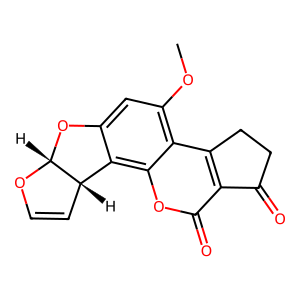

In [6]:
from rdkit.Chem.Draw import MolToImage

mol_image= Chem.MolFromSmiles(smiles)
# Chem.AllChem.Compute2DCoords(mol_image)
mol_image_numbered = MolToImage(mol_image,# includeAtomIDs=True,
                                size=(300, 300), atomLabelFontSize=25) # Aumentar el tamaño de la imagen y de la fuente de las etiquetas
mol_image_numbered

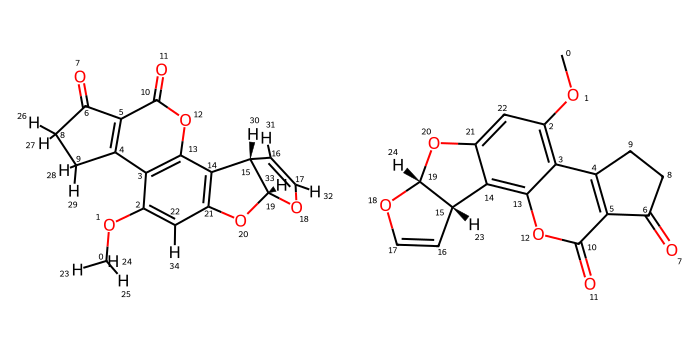

In [7]:
Draw.MolsToGridImage((mol, mol_image), subImgSize=(350,350), molsPerRow=2)

Mapa A: Potencial Electrostático (Cargas)

Gradiente: 'rwb' (Rojo $\rightarrow$ Blanco $\rightarrow$ Azul)

Escala: min: -0.4, max: 0.4

Rojo (Negativo, -0.4): Átomos electronegativos con carga parcial negativa, principalmente los nitrógenos del tetrazol y el oxígeno del alcohol.

Blanco (Neutro, 0.0): Carbonos con carga neutra o débilmente polarizados.

Azul (Positivo, +0.4): Átomos electropositivos con carga parcial positiva, principalmente el hidrógeno del grupo hidroxilo ($-\text{OH}$) y el carbono unido al cloro/nitrógenos.

In [17]:
view_a = py3Dmol.view(width=500, height=400)
view_a.addModel(pdb_cargas, 'pdb')
view_a.setStyle({'stick': {}})
view_a.addSurface('VDW', {
    'opacity': 0.8,
    'colorscheme': {'prop': 'b', 'gradient': 'rwb', 'min': -0.4, 'max': 0.4}
})
view_a.zoomTo()
view_a.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Las cargas en la superficie de potencial electrostático, tal como se visualizan aquí, se basan en las cargas parciales de Gasteiger. Estas cargas se expresan típicamente en unidades de carga elemental (e), o una fracción de la carga de un electrón. Indican la distribución de densidad electrónica en la molécula.




Mapa B: Lipofilicidad / Hidrofobicidad (LogP)

Gradiente: 'roygb' (Rojo $\rightarrow$ Naranja $\rightarrow$ Amarillo $\rightarrow$ Verde $\rightarrow$ Azul)

Escala: min: -0.5, max: 0.5

Rojo / Naranja (Valores negativos, -0.5): Regiones hidrofílicas / polares. Corresponde a los nitrógenos, el oxígeno del alcohol y los átomos polares que favorecen la solubilidad en agua.Amarillo (Valores neutros, 0.0): Transición entre carácter polar y apolar.

Verde / Azul (Valores positivos, +0.5): Regiones lipofílicas / hidrofóbicas. Corresponde a las zonas apolares como la cadena alifática de butilo y los anillos aromáticos de bifenilo.

In [10]:
view_b = py3Dmol.view(width=500, height=400)
view_b.addModel(pdb_logp, 'pdb')
view_b.setStyle({'stick': {}})
view_b.addSurface('VDW', {
    'opacity': 0.85,
    'colorscheme': {'prop': 'b', 'gradient': 'roygb', 'min': -0.5, 'max': 0.5}
})
view_b.zoomTo()
view_b.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Mapa C: Área Accesible al Solvente (SASA)

Gradiente: 'rwb' (Rojo $\rightarrow$ Blanco $\rightarrow$ Azul)

Escala (Invertida): min: 15.0, max: 0.0

Azul (Valores altos, 15.0 $\text{Å}^2$): Átomos altamente expuestos al solvente en la periferia exterior de la molécula (como los hidrógenos externos y el extremo de la cadena de butilo).

Blanco (Valores intermedios, ~7.5 $\text{Å}^2$): Átomos con exposición moderada.

Rojo (Valores bajos, 0.0 $\text{Å}^2$): Átomos enterados o protegidos, atrapados en el interior del núcleo molecular y sin contacto directo con el solvente.

In [11]:
view_c = py3Dmol.view(width=500, height=400)
view_c.addModel(pdb_sasa, 'pdb')
view_c.setStyle({'stick': {}})
view_c.addSurface('VDW', {
    'opacity': 0.85,
    'colorscheme': {'prop': 'b',
                    'gradient': 'rwb',
                    'min': 15.0, 'max': 0.0}
})
view_c.zoomTo()
view_c.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Mapa D: Refractividad Molar / Polarizabilidad

Gradiente: 'sinebow' (Arcoíris continuo: Morado $\rightarrow$ Azul $\rightarrow$ Verde $\rightarrow$ Amarillo $\rightarrow$ Rojo)

Escala: min: 0.0, max: 1.5

Morado / Azul (Valores bajos, ~0.0 - 0.3): Átomos con muy baja polarizabilidad, correspondiente a los hidrógenos y carbonos alifáticos simples.

Verde / Amarillo (Valores medios, ~0.4 - 0.8): Heteroátomos y carbonos con polarizabilidad intermedia.

Rojo (Valores altos, ~1.0 - 1.5): Átomos con alta polarizabilidad y alta densidad electrónica, principalmente el átomo de Cloro ($-\text{Cl}$) y los carbonos del sistema aromático conjugated/bifenilo.

In [12]:
view_d = py3Dmol.view(width=500, height=400)
view_d.addModel(pdb_refract, 'pdb')
view_d.setStyle({'stick': {}})
view_d.addSurface('VDW', {
    'opacity': 0.85,
    'colorscheme': {'prop': 'b', 'gradient': 'sinebow', 'min': 0.0, 'max': 1.5}
})
view_d.zoomTo()
view_d.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

# Sección nueva





Bloque 2: Predicción de Desplazamientos Químicos de RMN ($^1\text{H}$ y $^{13}\text{C}$)Este bloque identifica el entorno químico de cada átomo de Losartán, asigna el tipo de hibridación y grupo funcional, y calcula los desplazamientos químicos ($\delta$ ppm) para mostrar una tabla tabulada y limpia.Python

In [13]:
import pandas as pd
from rdkit import Chem

# Función para predecir rangos de desplazamiento químico (RMN) basados en reglas de aditividad/entorno
def estimar_rmn(mol):
    datos_nmr = []

    for atom in mol.GetAtoms():
        symbol = atom.GetSymbol()
        idx = atom.GetIdx()
        hyb = str(atom.GetHybridization())
        is_aromatic = atom.GetIsAromatic()

        # --- Predicción simplificada de RMN C-13 ---
        if symbol == 'C':
            if is_aromatic:
                # Modificación según heteroátomos vecinos
                vecinos = [a.GetSymbol() for a in atom.GetNeighbors()]
                if 'Cl' in vecinos:
                    delta_c = 134.5  # C-Cl aromático
                elif 'N' in vecinos:
                    delta_c = 148.0  # C-N aromático (imidazol)
                elif 'O' in vecinos:
                    delta_c = 155.0  # C-O aromático / bencílico
                else:
                    delta_c = 128.5  # Ar-H estándar
            elif hyb == 'SP3':
                vecinos = [a.GetSymbol() for a in atom.GetNeighbors()]
                if 'O' in vecinos:
                    delta_c = 62.0   # -CH2-OH (Alcohol bencílico)
                elif 'N' in vecinos:
                    delta_c = 48.5   # -CH2-N-
                else:
                    # Cadena de Butilo (alifática)
                    delta_c = 14.0 + (10.0 * atom.GetDegree())
            elif hyb == 'SP2':
                delta_c = 156.0  # Carbonos C=N del Tetrazol / Imidazol
            else:
                delta_c = 100.0

            datos_nmr.append({
                'Índice Átomo': idx,
                'Núcleo': '13C',
                'Entorno / Grupo': f"Carbono {hyb} {'Aromático' if is_aromatic else 'Alifático'}",
                'δ Estimado (ppm)': round(delta_c, 2)
            })

        # --- Predicción simplificada de RMN H-1 ---
        elif symbol == 'H':
            vecino = atom.GetNeighbors()[0]
            if vecino.GetIsAromatic():
                delta_h = 7.35   # Protones Aromáticos
            else:
                vecinos_c = [a.GetSymbol() for a in vecino.GetNeighbors()]
                if 'O' in vecinos_c:
                    delta_h = 4.60  # Protones -CH2-OH o -OH
                elif 'N' in vecinos_c:
                    delta_h = 5.25  # Protones -CH2-N
                else:
                    delta_h = 0.90 + (0.4 * vecino.GetDegree()) # Cadena Butilo

            datos_nmr.append({
                'Índice Átomo': idx,
                'Núcleo': '1H',
                'Entorno / Grupo': f"Protón unido a {vecino.GetSymbol()}{vecino.GetIdx()}",
                'δ Estimado (ppm)': round(delta_h, 2)
            })

    return pd.DataFrame(datos_nmr)

# Generar tabla
df_nmr = estimar_rmn(mol)

# Mostrar resumen de C-13 y H-1 por separado
print("="*60)
print("   ESTIMACIÓN DE DESPLAZAMIENTOS QUÍMICOS DE RMN (13C)")
print("="*60)
print(df_nmr[df_nmr['Núcleo'] == '13C'].head(15).to_string(index=False))

print("\n" + "="*60)
print("   ESTIMACIÓN DE DESPLAZAMIENTOS QUÍMICOS DE RMN (1H)")
print("="*60)
print(df_nmr[df_nmr['Núcleo'] == '1H'].head(15).to_string(index=False))

   ESTIMACIÓN DE DESPLAZAMIENTOS QUÍMICOS DE RMN (13C)
 Índice Átomo Núcleo       Entorno / Grupo  δ Estimado (ppm)
            0    13C Carbono SP3 Alifático              62.0
            2    13C Carbono SP2 Aromático             155.0
            3    13C Carbono SP2 Aromático             128.5
            4    13C Carbono SP2 Alifático             156.0
            5    13C Carbono SP2 Alifático             156.0
            6    13C Carbono SP2 Alifático             156.0
            8    13C Carbono SP3 Alifático              54.0
            9    13C Carbono SP3 Alifático              54.0
           10    13C Carbono SP2 Alifático             156.0
           13    13C Carbono SP2 Aromático             155.0
           14    13C Carbono SP2 Aromático             128.5
           15    13C Carbono SP3 Alifático              54.0
           16    13C Carbono SP2 Alifático             156.0
           17    13C Carbono SP2 Alifático             156.0
           19    13C Carbono S

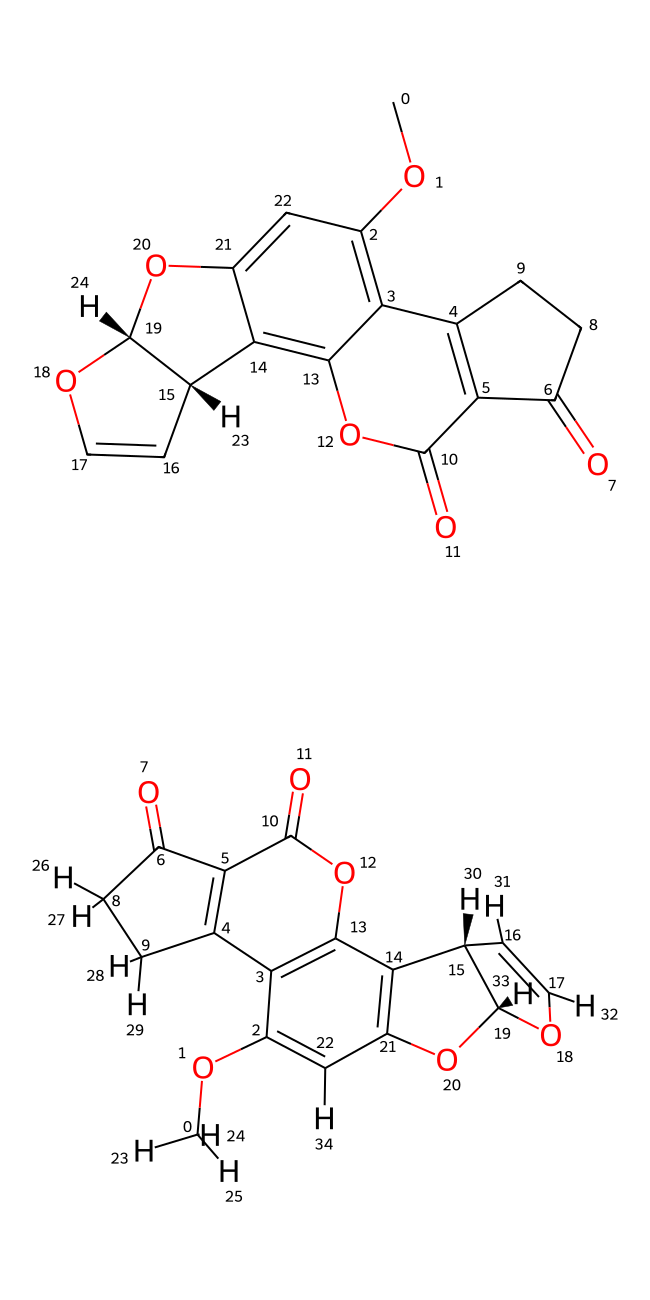

In [14]:
Draw.MolsToGridImage((mol_image, mol), subImgSize=(650,650), molsPerRow=1, )

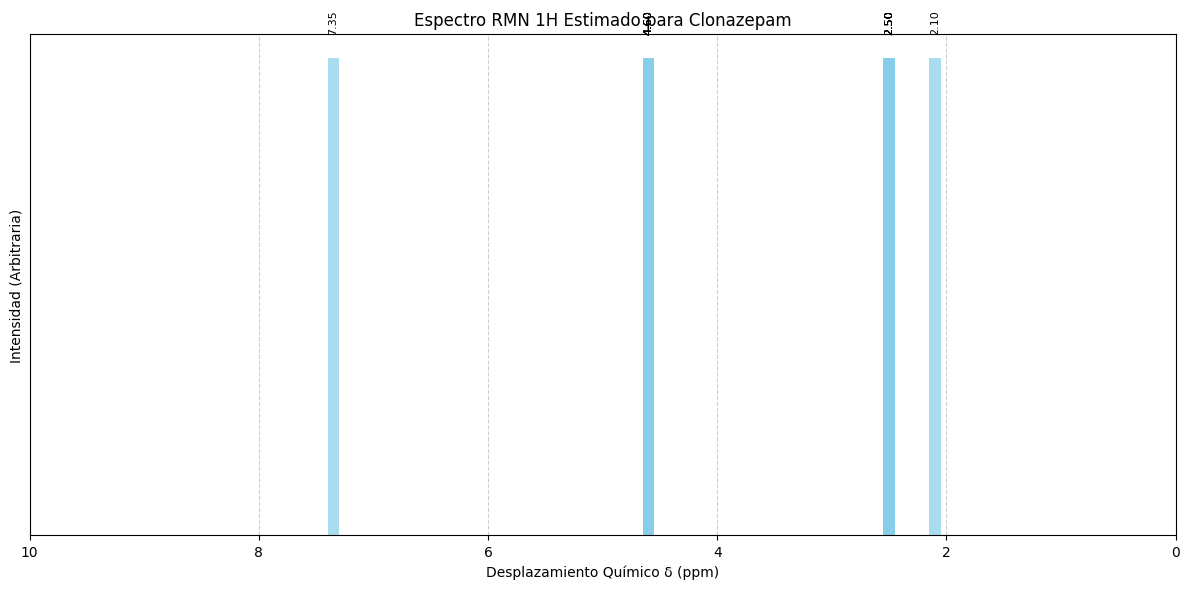

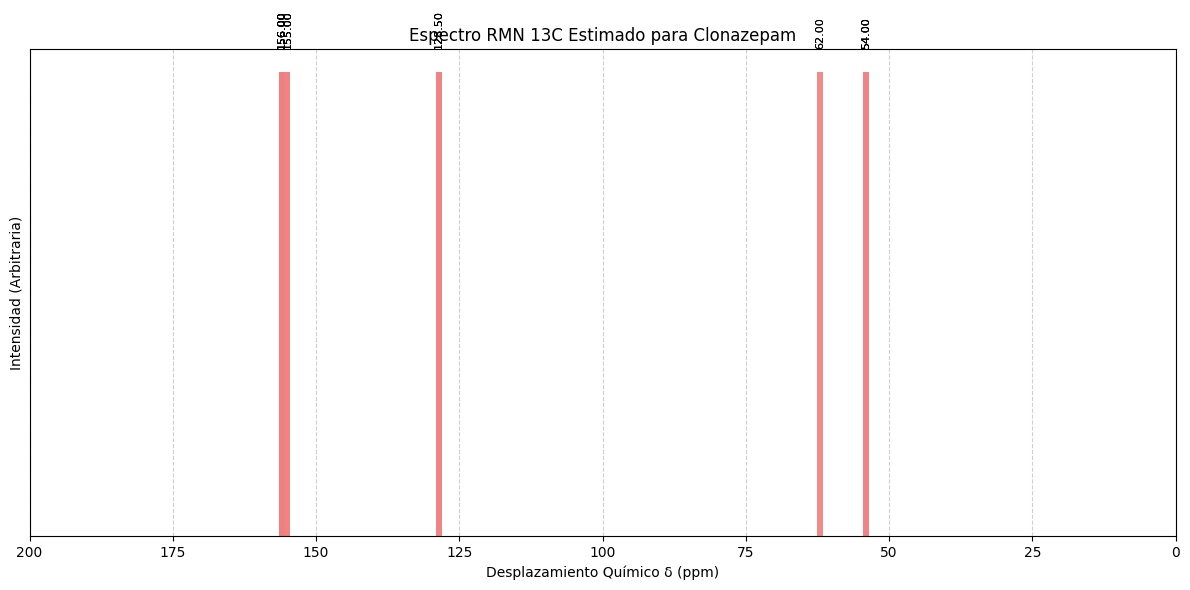

In [15]:
import matplotlib.pyplot as plt

# Filtrar datos para 1H y 13C
df_nmr_1h = df_nmr[df_nmr['Núcleo'] == '1H'].sort_values(by='δ Estimado (ppm)')
df_nmr_13c = df_nmr[df_nmr['Núcleo'] == '13C'].sort_values(by='δ Estimado (ppm)')

# ==============================================================================
# 1. Gráfico de Espectro de RMN 1H
# ==============================================================================
plt.figure(figsize=(12, 6))
plt.bar(df_nmr_1h['δ Estimado (ppm)'], [1]*len(df_nmr_1h), width=0.1, color='skyblue', alpha=0.7)
plt.xlabel('Desplazamiento Químico δ (ppm)')
plt.ylabel('Intensidad (Arbitraria)')
plt.title('Espectro RMN 1H Estimado para Clonazepam')
plt.xlim(0.0, 10.0) # Modificado a 10 ppm
plt.yticks([]) # Ocultar ticks del eje Y para una apariencia de espectro
plt.gca().invert_xaxis() # Invertir el eje X para el RMN
plt.grid(axis='x', linestyle='--', alpha=0.6)

# Añadir etiquetas de ppm para cada pico
for i, row in df_nmr_1h.iterrows():
    plt.text(row['δ Estimado (ppm)'], 1.05, f"{row['δ Estimado (ppm)']:.2f}", ha='center', va='bottom', fontsize=8, rotation=90)

plt.tight_layout()
plt.show()

# ==============================================================================
# 2. Gráfico de Espectro de RMN 13C
# ==============================================================================
plt.figure(figsize=(12, 6))
plt.bar(df_nmr_13c['δ Estimado (ppm)'], [1]*len(df_nmr_13c), width=1.0, color='lightcoral', alpha=0.7)
plt.xlabel('Desplazamiento Químico δ (ppm)')
plt.ylabel('Intensidad (Arbitraria)')
plt.title('Espectro RMN 13C Estimado para Clonazepam')
plt.xlim(0.0, 200.0) # Modificado a 200 ppm
plt.yticks([]) # Ocultar ticks del eje Y para una apariencia de espectro
plt.gca().invert_xaxis() # Invertir el eje X para el RMN
plt.grid(axis='x', linestyle='--', alpha=0.6)

# Añadir etiquetas de ppm para cada pico
for i, row in df_nmr_13c.iterrows():
    plt.text(row['δ Estimado (ppm)'], 1.05, f"{row['δ Estimado (ppm)']:.2f}", ha='center', va='bottom', fontsize=8, rotation=90)


plt.tight_layout()
plt.show()

In [16]:
import os
import urllib.request
import tarfile
import pandas as pd
import py3Dmol
from rdkit import Chem

# ==============================================================================
# 1. DESCARGAR E INSTALAR xTB DIRECTAMENTE (BINARIO OFICIAL)
# ==============================================================================
print("Descargando e instalando xTB...")
xtb_url = "https://github.com/grimme-lab/xtb/releases/download/v6.6.1/xtb-6.6.1-linux-x86_64.tar.xz"
tar_path = "xtb.tar.xz"

if not os.path.exists("xtb_dist"):
    urllib.request.urlretrieve(xtb_url, tar_path)
    with tarfile.open(tar_path, "r:xz") as tar:
        tar.extractall("xtb_dist")

# Configurar variables de entorno para que el sistema reconozca xTB
xtb_bin_dir = os.path.abspath("xtb_dist/xtb-6.6.1/bin")
os.environ["PATH"] += f":{xtb_bin_dir}"

# ==============================================================================
# 2. EXPORTAR LOSARTÁN A XYZ Y EJECUTAR XTB
# ==============================================================================
xyz_block = Chem.MolToXYZBlock(mol)
with open("losartan.xyz", "w") as f:
    f.write(xyz_block)

print("Ejecutando cálculo cuántico GFN2-xTB para Losartán...")
os.system(f"{xtb_bin_dir}/xtb losartan.xyz --opt > xtb_output.log 2>&1")

# ==============================================================================
# 3. EXTRAER ENERGÍAS HOMO Y LUMO DEL ARCHIVO DE SALIDA
# ==============================================================================
e_homo, e_lumo = None, None

if os.path.exists("xtb_output.log"):
    with open("xtb_output.log", "r") as f:
        for line in f:
            if "(HOMO)" in line:
                parts = line.split()
                # La energía HOMO suele ser el penúltimo valor (en eV)
                e_homo = float(parts[-2])
            elif "(LUMO)" in line:
                parts = line.split()
                # La energía LUMO suele ser el penúltimo valor (en eV)
                e_lumo = float(parts[-2])

# ==============================================================================
# 4. CÁLCULO DE INDICADORES GLOBALES DE REACTIVIDAD (DFT CONCEPTUAL)
# ==============================================================================
if e_homo is not None and e_lumo is not None:
    gap = e_lumo - e_homo                   # Gap HOMO-LUMO (eV)
    ip = -e_homo                            # Potencial de Ionización (eV)
    ea = -e_lumo                            # Afinidad Electrónica (eV)
    chi = (ip + ea) / 2.0                  # Electronegatividad (eV)
    eta = (ip - ea) / 2.0                  # Dureza Química (eV)
    omega = (chi**2) / (2.0 * eta)         # Índice de Electrofilia (eV)

    print("\n" + "="*55)
    print("   INDICADORES GLOBALES DE REACTIVIDAD (GFN2-xTB)")
    print("="*55)
    print(f"  Energía HOMO (E_HOMO)  : {e_homo:.4f} eV")
    print(f"  Energía LUMO (E_LUMO)  : {e_lumo:.4f} eV")
    print(f"  Gap Energético (ΔE)    : {gap:.4f} eV")
    print(f"  Electronegatividad (χ): {chi:.4f} eV")
    print(f"  Dureza Química (η)     : {eta:.4f} eV")
    print(f"  Índice Electrofilia (ω): {omega:.4f} eV")
    print("="*55 + "\n")
else:
    print("\n❌ Ocurrió un error al leer la salida de xTB. Revisa el archivo 'xtb_output.log'.")

# ==============================================================================
# 5. VISUALIZACIÓN DE LA ESTRUCTURA OPTIMIZADA POR MECÁNICA CUÁNTICA
# ==============================================================================
view_qm = py3Dmol.view(width=500, height=400)
if os.path.exists("xtbopt.log"):
    with open("xtbopt.log", "r") as f:
        opt_xyz = f.read()
    view_qm.addModel(opt_xyz, 'xyz')
else:
    view_qm.addModel(Chem.MolToPDBBlock(mol), 'pdb')

view_qm.setStyle({'stick': {'radius': 0.18}})
view_qm.zoomTo()
view_qm.show()

Descargando e instalando xTB...


/tmp/ipykernel_2650/1382905172.py:18: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall("xtb_dist")


Ejecutando cálculo cuántico GFN2-xTB para Losartán...

   INDICADORES GLOBALES DE REACTIVIDAD (GFN2-xTB)
  Energía HOMO (E_HOMO)  : -10.6336 eV
  Energía LUMO (E_LUMO)  : -8.2837 eV
  Gap Energético (ΔE)    : 2.3499 eV
  Electronegatividad (χ): 9.4586 eV
  Dureza Química (η)     : 1.1749 eV
  Índice Electrofilia (ω): 38.0723 eV



3Dmol.js failed to load for some reason. Please check your browser console for error messages.